# Day 6 - Quantum Error Correction Technique : CSS(CalderBank-Shor-Steane) Code

The notebook below demonstrate the implementation of CSS code: Protecting quantum information from bit flip(X) and phase flip(Z) error detection. it uses a padagogical  nine qubit shoe code construction ,which is a CSS code to demonstrate the encoding ,stabilizer syndrom extraction ,error correction and logical measurement comparision. The implemenation uses Qiskit circuit and statevector based simulation with explicit puali error .this kept the example reproducible and avoids relying on a perticular external quantum simulator package .

CSS code are family of quantum error correcting code constructed using ideas from classical error correcting code .Their key advantage is that they allows bit flip errors and phase flip errors to be detected and corrected through seperate sets of stabilizer checks.In this notebook ,we will explore the CSS principles ,using three qubit bit flip repitition code ,a simple CSS stabilizer code example ,we will encode logical state ,delibratly introduced a bil flip errors.extracts its error syndrome using ancilla qubits and apply a correction.we will covers:
- The motivation  and construction of CSS code 
- Binary parity checks and stabilizers operators 
- Quantum circuit encoding and syndrome extraction in Qiskit
- Error identification and correction
- Measurement count visualization before and after correction

This notebook help to understand how syndrome measurement reaveal error information without directlt measuring the encoded logical state and how is this process form part of broder CSS error correction scheme.

## Introduction to CSS code
A Qubit can experience two types of Fundamental Pauli errors:
- **Bit Flip Errors(X)** : change $\rvert0\rangle$ to $\rvert1\rangle$ and vice versa.
- **Phase flip errors(Z)** : Change the relative phase of superposition example,$\rvert+\rangle$ to $\rvert-\rangle$

A general quntum erro can involve both type as well as their cobination $Y=iXZ$

CSS code uses a classical binary error correcting code to handle this error type seperatly .one family of stabilizers checls detects bit-flip error while other detects phase-flip erros.

In this notebook we will implements the bit flip sector of the CSS approch using three physical qubit.This small exmaple illustrate  the encoding and syndrome decoding workflow without the complexity of arger code such as seven qubit Steane code.

- **Terminology**

- **Logical Qubit** : The qunatum information being protected
- **Physical Qubit** : A qubit is used to encode that information
- **Ancilla Qubit** : An auxillary qubit used to extract the error information
- **Syndrome** : A set of measurement outome that helps identify an error
- **Stabilizers** : an operator whose expected valus is preserve by the encoded code space.

### Mathematical Background 
##### Three Qubit bit flip code :
The logical basis states are :
         $\rvert0_L\rangle = \rvert000\rangle$ , $\rvert1_L\rangle = \rvert111\rangle$ .

An arbitary Logical state is encoded as:
         $\rvert\psi_L\rangle = \alpha\rvert000\rangle + \alpha\rvert111\rangle$ , $\rvert\alpha\lvert^2 +\rvert\beta \lvert^2$

The code uses a two stabilizers checks:
         $S_1=Z_0Z_1$ ,   $S_2=Z_1Z_2$

Both stabilizers have eigevalue +1 for valid code state .their measurement outcome reveale the parity of neighboring pysical qubit without directly measuring the logical information.

**Syndrome (s1,s2)**$\rightarrow $     **Error Identification**

(0,0)$\rightarrow $ No-bit flip

(1,0) $\rightarrow $ X0

(1,1) $\rightarrow $ X1

(0,1) $\rightarrow $ X2

Here syndrome bit +1 indicate the stabilizer outcome -1 and bit bit 0 indicates +1.

This three qubit code corrects one bit flip error but does nit correct arbitary pahase flip error .A complete CSS construction combines suitable bit-flip and phase-flip protection.
         

## Import Required Libraries


In [1]:
from qiskit import QuantumCircuit,transpile
from qiskit_aer import AerSimulator
import matplotlib.pyplot as plt
simulator=AerSimulator()
shots=1024
print("Qiskit CSS code Demonstarion Initialized")

Qiskit CSS code Demonstarion Initialized


## Step 1 : Encode the Logical State
We begin with three physical Qubit initialized to $\rvert000\rangle$. The firts Qubit carries the initail logical information and two CNOT gate spread its computationla basis value across the other Qubits.
 for this experiments ,we use the Logical input $\rvert0\rangle$  which becomes $\rvert000\rangle$..using the knowns inputs makes the effects of delibratly introduced errors straigh forward to inspect .THe circuit below prepares the encoded state .The same encoding sequence will be reused in the following experiments.

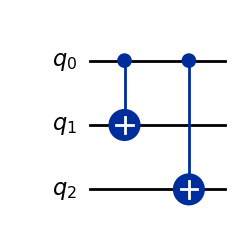

In [2]:
def prepare_encode_state():
    # Encode a compuatational-basis logical input into three qubits
    qc=QuantumCircuit(3)
    qc.cx(0,1)
    qc.cx(0,2)
    return qc
encoding_circuit=prepare_encode_state()
encoding_circuit.draw("mpl")

## Introduced Bit-Flip Error
We delibaretely  apply $X_0$  to physical qubit 0 after encoding.The encoded state changes from $\rvert000\rangle$  to $\rvert100\rangle$. where the left to right ket notation corrosponds to qubit 2,1 and 0.
This controlled error simulate a single physical fault,we first measure the resulting  data qubit withour applying the correction,creating a baseline against we compare the corrected output.

In [3]:
def build_data_circuit(correct=False):
    #Prepare the encoded input ,inject X0 and optionally correct it.
    qc=QuantumCircuit(3,3)
    qc.cx(0,1)
    qc.cx(0,2)
    #Delibaretly inject  a bit flip error on physical qubit 0
    qc.x(0)

    if correct:
        #Apply the correction identified by the syndrome
        qc.x(0)
    qc.measure([0,1,2],[0,1,2])
    return qc

uncorrected_circuit=build_data_circuit(correct=False)
uncorrected_counts=simulator.run(transpile(uncorrected_circuit,simulator),shots=shots).result().get_counts()
print("measurement count before correction")
print(uncorrected_counts)

measurement count before correction
{'001': 1024}


## Step 3 - Extract the Error Syndrome
To identify the error ,we measure the two satbilizers $Z_0Z_1$ and $Z_1Z_2$ using ancilla qubits. For each parity checks ,the corrosponding data qubits controls CNOT gates targeting an ancilla initialized to $\rvert0\rangle$ .Measuring the ancilla revearls whether the two data qubit have two equal or different compational basis values.

The syndrome circuit uses three data qubits and two ancillas .The data qubits are not directly measured during this stage ,so the syndrome extraction does not reveals the logical computational basis valus itslef. For the injected $X_0$  errors ,we expect syndrome (1,0) in stabilizer order $(S_1S_2)$ .



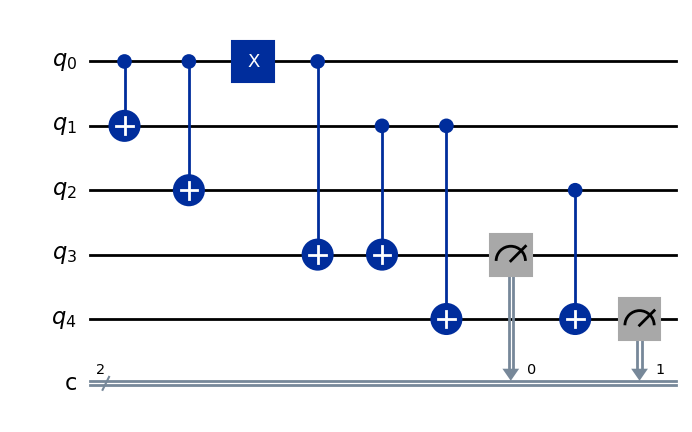

In [4]:
def build_syndrome_circuit():
    #Measure Z0Z1 and Z1Z2 using two ancillas
    qc=QuantumCircuit(5,2)

    #Encode |0> into three qubit repetition code 
    qc.cx(0,1)
    qc.cx(0,2)

    #Inject X0 on data qubit 0
    qc.x(0)

    #Ancilla q3 measure Z0Z1 parity
    qc.cx(0,3)
    qc.cx(1,3)

    #Ancilla q4 measured Z1Z2 parity
    qc.cx(1,4)
    qc.cx(2,4)

    # c0 stores the first check: C1 stores the second checks
    qc.measure(3,0)
    qc.measure(4,1)
    return qc

syndrome_circuit=build_syndrome_circuit()
syndrome_circuit.draw("mpl")

## Step 4 -Run The Syndrome Measurement
We execute the syndrome circuit on Qiskit Aer , a local quantum -circuit simulator ,The resulting count distribution shows how frequently each syndrome is observed . Qiskit diaplay classical bit string with the highest -indexed classical bit on the left .Therefore ,the displayed string is ordered as c1c0 .even though checks were stored in c0,c1 order.

for the determines error used here ,the expeted displayed syndrome is 01: the first parity checks detect the errors while seconf does not.

In [5]:
syndrome_counts=simulator.run(transpile(syndrome_circuit,simulator),shots=shots).result().get_counts()
print("Syndrome measurement counts")
print(syndrome_counts)
most_common_syndrome=max(syndrome_counts,key=syndrome_counts.get)
print("Most frequently observed Syndrome",most_common_syndrome)

Syndrome measurement counts
{'01': 1024}
Most frequently observed Syndrome 01


## Step 5 - Apply the Correction
The syndroem identifies the location of the bit-flip error .since the first satbilzer reports odd parity and second stabilizers report even parity,the error is assigned to physical qubit 0.

We apply $X_0$ again because $X^2=I$ ,applying the same bit flip operations twice restore the original encoded state.

For the clarity this notebook uses a two stage demonstartion .the syndrome is measured first and corrospnding correction is then applied seperate circuit . In an automated error correction system,classical decoding logic would use the syndrome to selectthe correction dynamically.

In [7]:
corrected_circuit=build_data_circuit(correct=True)
corrected_counts=simulator.run(transpile(corrected_circuit,simulator),shots=shots).result().get_counts()
print("Measurement counts  after correction")
print(corrected_counts)

Measurement counts  after correction
{'000': 1024}


## Visualization of Result

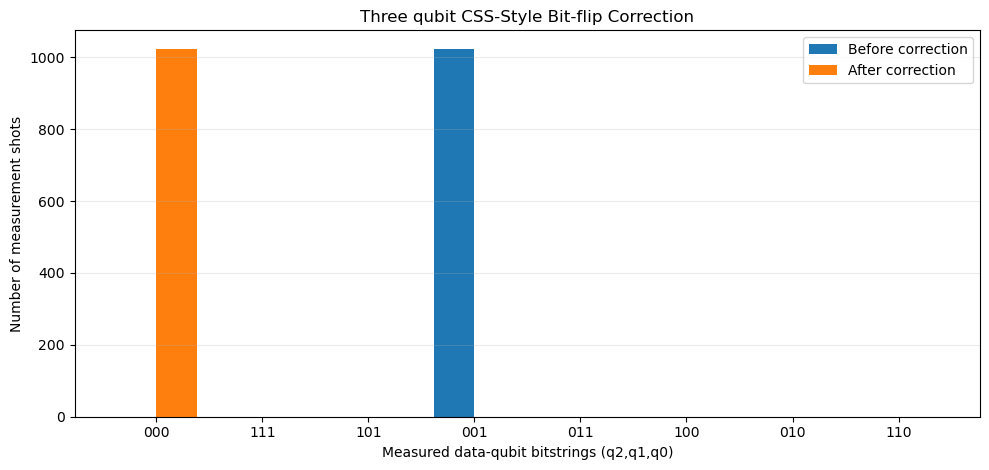

In [10]:
#Compare data measurement distribution before and after correction
bitstrings={format(i,"03b") for i in range(8)}
before=[uncorrected_counts.get(bits,0) for bits in bitstrings]
after=[corrected_counts.get(bits,0) for bits in bitstrings]
x=list(range(len(bitstrings)))
width=0.38
fig,ax=plt.subplots(figsize=(10,4.8))
ax.bar([i-width/2 for i in x],before,width,label="Before correction")
ax.bar([i+width/2 for i in x],after,width,label="After correction")

ax.set_xticks(x)
ax.set_xticklabels(bitstrings)
ax.set_xlabel("Measured data-qubit bitstrings (q2,q1,q0)")
ax.set_ylabel("Number of measurement shots")
ax.set_title("Three qubit CSS-Style Bit-flip Correction")
ax.legend()
ax.grid(axis="y",alpha=0.25)
plt.tight_layout()
plt.show()

## Result Interpretation
#### What the Visualization Shows
- **X-axis**: The measured three-qubit bitstring diaplayed q2,q1,q0 order.
- **Y-axis**: The number of measurement shots producing each bitstrings.
- **Before Correction** : the injected $X_0$  error changes the encoded input from $\rvert000\rangle$ to $\rvert100\rangle$ represented by the masurement string 100
- **After Correction** : Applying $X_0$  again restore $\rvert000\rangle$ reperensted by 000

for this ideal deterministic simulation  measurement distribution should move from 001  before correction 000 after correction ,the syndrome measurement should also produced 01.identify the error on qubit 0.

## Conclusion
Calderbank-Shor-Steane(CSS)code uses classical error correction code ideas to protect qunatum information.they seperate the bit flip code and phase flip code error error detection ito distinct families of stabilizers checks ,simplifying the design of qunatum errro correction precedure.

In this notebook ,we implements the three qubit bit flip repetition code as simple CSS stabilizer code example .using Qiskit,we encoded a logical input introduced a controlled bit flip error,extracted the syndrome ancillas qubits and apply the correction .

The measurement comarision demonstrated that the injected error could be identified and corrected under ideal simualtion condition .his three qubit example protects only against single bit flip error ,it does not provide complete quantum error correction against arbitary error.

**Key takeaway** :
CSS code transform the problem of identifying quantum errors into structured syndrome-decoding problems. 

---

**Author:** *Shreya Palase*  

**Date Created:**  *27-sep-2026*

**project:** Quantum-Error-Correction-Techniques

**File:** Day06-CSS_Code.ipynb

Thank you and Keep Learning!

<sub>© Shreya Palase- All Rights Reserved.This notebook is part of a structured learning series designed for Github publication.</sub>